In [286]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [287]:
df_proficiencia_serasp_2011 = pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2011_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2012=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2012_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2013=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2013_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2014=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2014_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2015=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2015_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2016=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2016_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2017=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2017_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2018=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2018_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2019=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2019.csv',sep=';',encoding='latin-1',)
df_proficiencia_serasp_2021=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2021_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2022=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2022_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2023=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2023.csv',sep=';',encoding='utf-8')
df_proficiencia_serasp_2024=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2024_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2025=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2025_0.csv',sep=';',encoding='utf-8')

In [288]:
list_proficiencia_saresp=[df_proficiencia_serasp_2011,df_proficiencia_serasp_2012,df_proficiencia_serasp_2013,df_proficiencia_serasp_2014,df_proficiencia_serasp_2015,df_proficiencia_serasp_2016,df_proficiencia_serasp_2017,df_proficiencia_serasp_2018,df_proficiencia_serasp_2019,df_proficiencia_serasp_2021,df_proficiencia_serasp_2022,df_proficiencia_serasp_2023,df_proficiencia_serasp_2024,df_proficiencia_serasp_2025]

In [289]:
for dataframe in list_proficiencia_saresp:
    for coluna in dataframe:
        if coluna== 'MEDPROF':
            dataframe['MEDPROF-N'] = pd.to_numeric(
            dataframe['MEDPROF'].astype(str).str.replace(',', '.', regex=False),
            errors='raise')
        if coluna== 'medprof':
            dataframe['MEDPROF-N'] = pd.to_numeric(
            dataframe['medprof'].astype(str).str.replace(',', '.', regex=False),
            errors='raise')


In [290]:
df_proficiencia_serasp_2019.info()


<class 'pandas.DataFrame'>
RangeIndex: 20297 entries, 0 to 20296
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ï»¿DEPADM   20297 non-null  int64  
 1   DepBol      20297 non-null  int64  
 2   NomeDepBol  20297 non-null  str    
 3   CodRMet     20297 non-null  int64  
 4   CODESC      20297 non-null  int64  
 5   NOMESC      20297 non-null  str    
 6   SERIE_ANO   20297 non-null  str    
 7   cod_per     20297 non-null  int64  
 8   periodo     20297 non-null  str    
 9   co_comp     20297 non-null  int64  
 10  ds_comp     20297 non-null  str    
 11  medprof     20297 non-null  str    
 12  MEDPROF-N   20297 non-null  float64
dtypes: float64(1), int64(6), str(6)
memory usage: 2.0 MB


In [326]:
series = ['7º Ano EF', '9º Ano EF', 'EM-3ª série', '5º Ano EF']
cont = 2011
lista_dataframes = []

for dataframe in list_proficiencia_saresp:

    if cont == 2020:
        cont += 1

    # Remove espaços dos nomes das colunas
    dataframe.columns = dataframe.columns.str.strip()

    # Identifica a coluna da disciplina, independentemente de maiúsculas/minúsculas
    colunas = {col.upper(): col for col in dataframe.columns}

    if 'DS_COMP' in colunas:
        coluna_comp = colunas['DS_COMP']

        # Verifica se as colunas necessárias existem
        if all(col in dataframe.columns for col in ['MEDPROF-N', 'SERIE_ANO']):

            x = dataframe.loc[
                dataframe[coluna_comp].astype(str).str.strip().str.upper() == 'MATEMÁTICA',
                ['MEDPROF-N', 'SERIE_ANO']
            ].copy()

            x['ANO'] = cont

            x['MEDPROF-N'] = x['MEDPROF-N'].fillna(
                x['MEDPROF-N'].mean()
            )

            lista_dataframes.append(x)

        else:
            print(f'Ano {cont}: colunas ausentes.')

    else:
        print(f'Ano {cont}: coluna DS_COMP não encontrada.')

    cont += 1

In [292]:
for dfi in lista_dataframes:
    print(dfi)

        MEDPROF-N    SERIE_ANO   ANO
1           207.2    7º Ano EF  2011
5           207.2    7º Ano EF  2011
9           238.3    9º Ano EF  2011
13          238.3    9º Ano EF  2011
17          282.0  EM-3ª série  2011
...           ...          ...   ...
139045      169.2    5º Ano EF  2011
139047      213.9    5º Ano EF  2011
139049      213.9    5º Ano EF  2011
139051      213.1    5º Ano EF  2011
139053      213.1    5º Ano EF  2011

[40399 rows x 3 columns]
        MEDPROF-N    SERIE_ANO   ANO
1           217.9    7º Ano EF  2012
4           217.9    7º Ano EF  2012
7           230.1    9º Ano EF  2012
10          230.1    9º Ano EF  2012
13          281.4  EM-3ª série  2012
...           ...          ...   ...
110007      236.3    9º Ano EF  2012
110010      211.2    5º Ano EF  2012
110012      211.2    5º Ano EF  2012
110014      205.0    5º Ano EF  2012
110016      205.0    5º Ano EF  2012

[40355 rows x 3 columns]
        MEDPROF-N  SERIE_ANO   ANO
1           210.0  7º Ano

In [293]:
print(df_proficiencia_serasp_2019['SERIE_ANO'].unique())

<StringArray>
['9Âº Ano EF', '7Âº Ano EF', '5Âº Ano EF', 'EM-3Âª sÃ©rie']
Length: 4, dtype: str


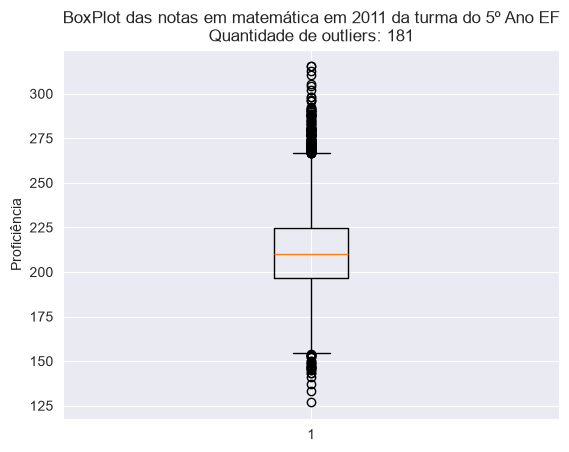

<Figure size 640x480 with 0 Axes>

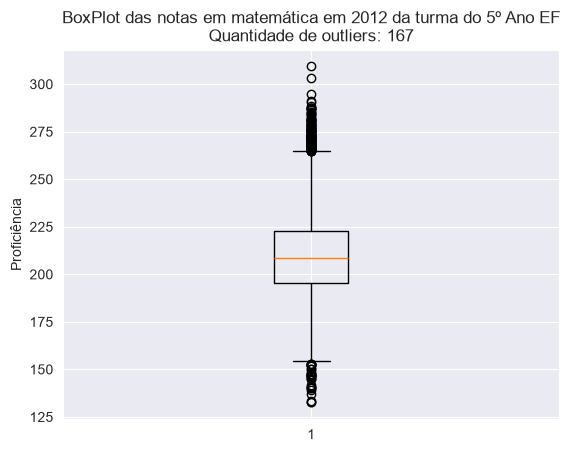

<Figure size 640x480 with 0 Axes>

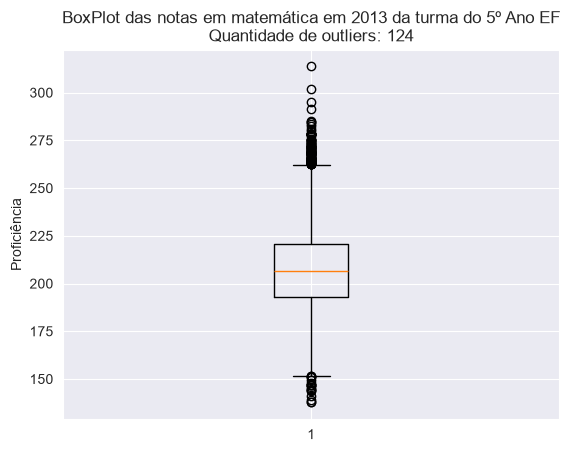

<Figure size 640x480 with 0 Axes>

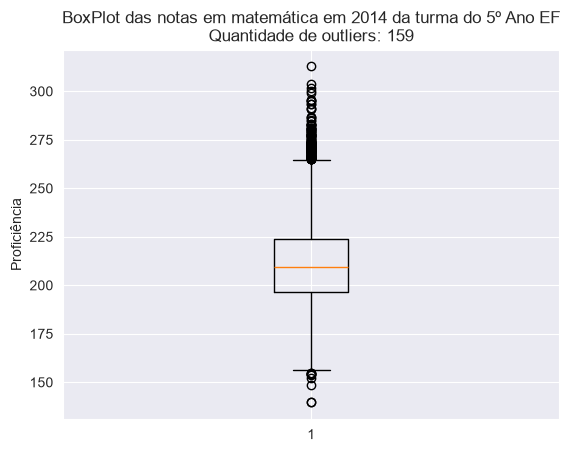

<Figure size 640x480 with 0 Axes>

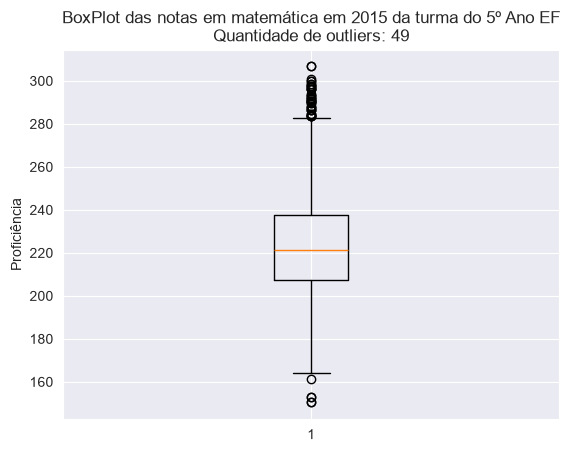

<Figure size 640x480 with 0 Axes>

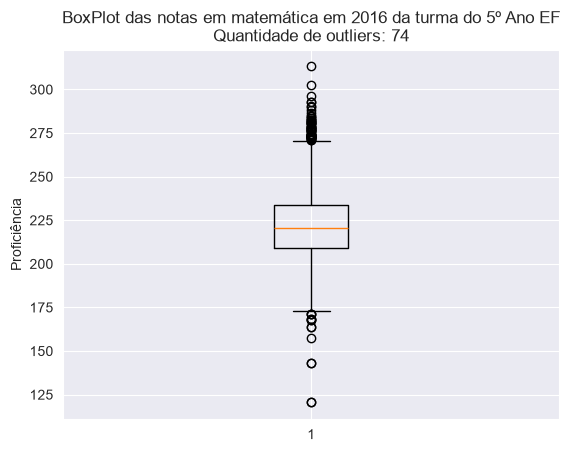

<Figure size 640x480 with 0 Axes>

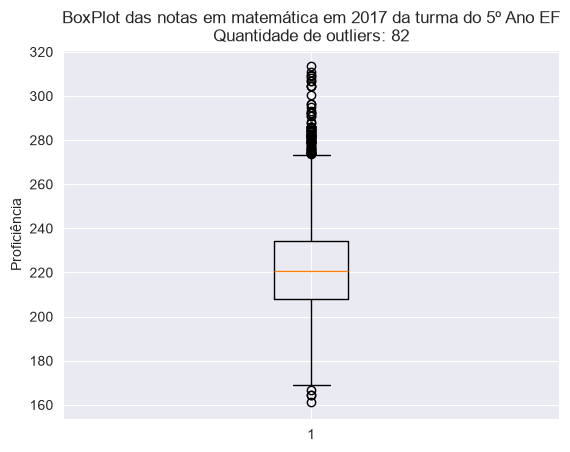

<Figure size 640x480 with 0 Axes>

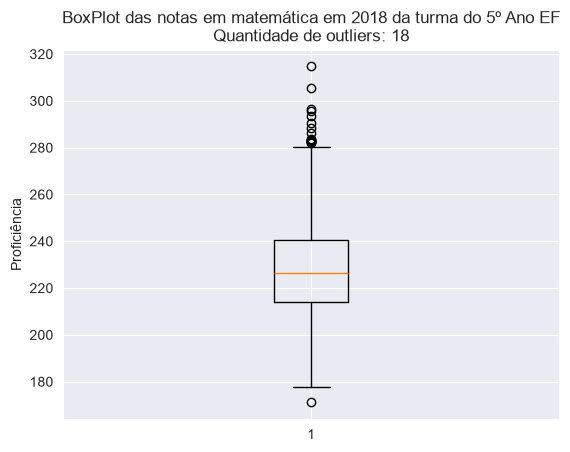

<Figure size 640x480 with 0 Axes>

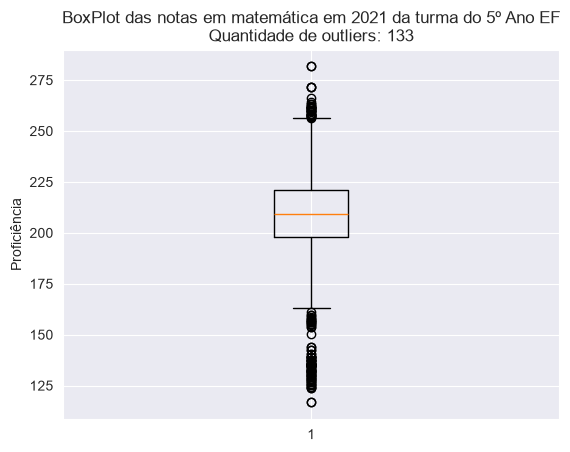

<Figure size 640x480 with 0 Axes>

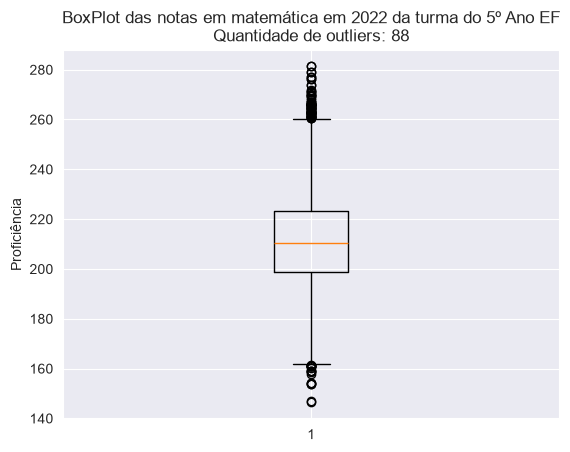

<Figure size 640x480 with 0 Axes>

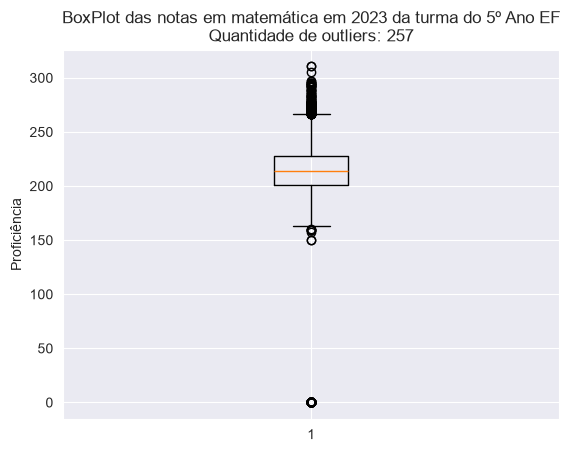

<Figure size 640x480 with 0 Axes>

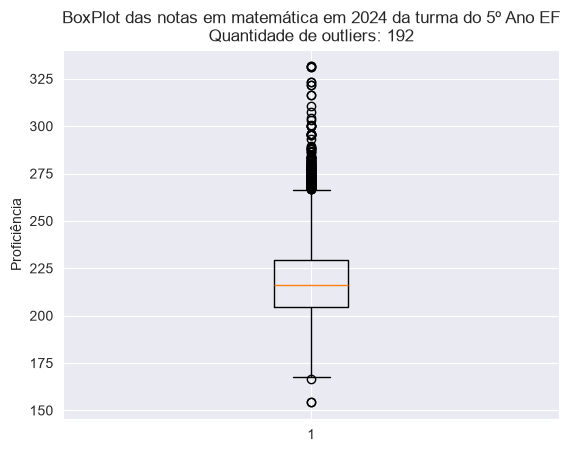

<Figure size 640x480 with 0 Axes>

In [322]:
for dfi in lista_dataframes:
    x = dfi.loc[
        dfi['SERIE_ANO'].str.contains('5.*Ano EF', regex=True, na=False),
        'MEDPROF-N'
    ].dropna()

    if x.empty:
        continue

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = x[(x < limite_inferior) | (x > limite_superior)]

    plt.figure()
    plt.boxplot(x)
    plt.title(
        f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]} "
        f"da turma do 5º Ano EF\n"
        f"Quantidade de outliers: {len(outliers)}"
    )
    plt.ylabel('Proficiência')
    plt.show()
    #plt.savefig(f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]}.png", dpi=300, bbox_inches='tight')

Não vou plotar 2015

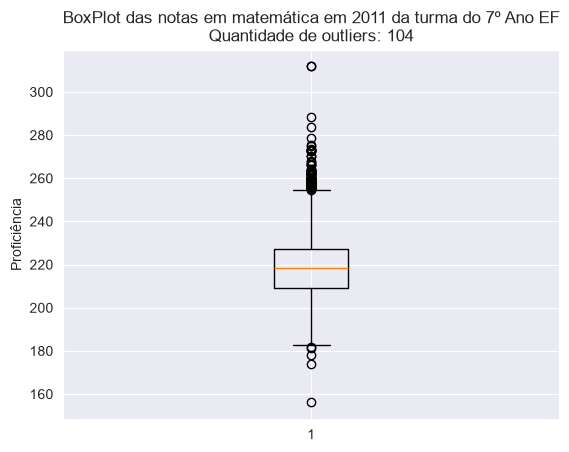

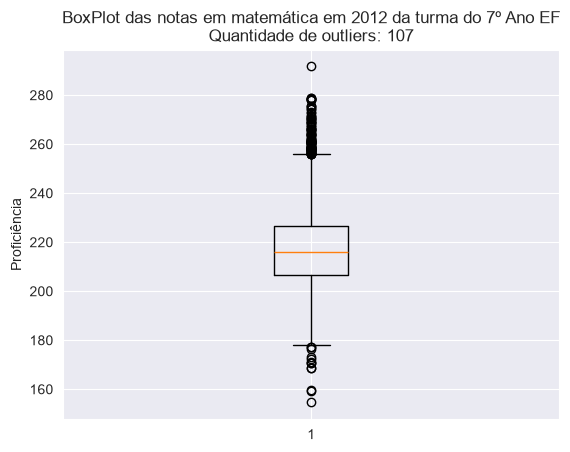

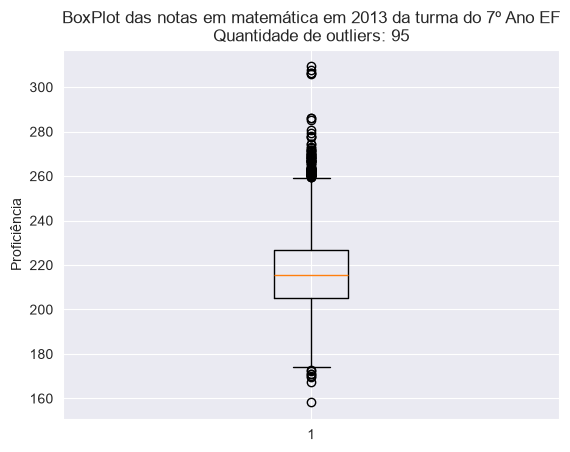

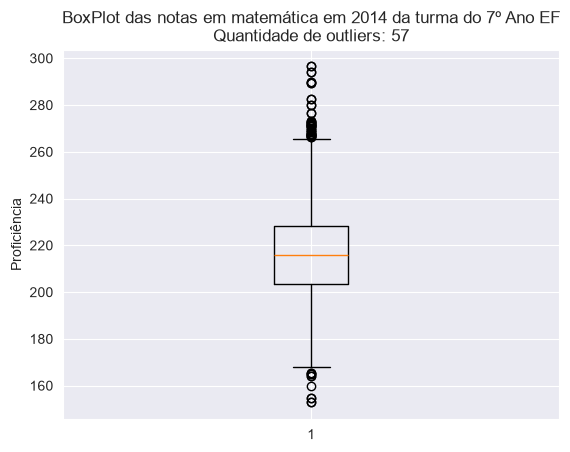

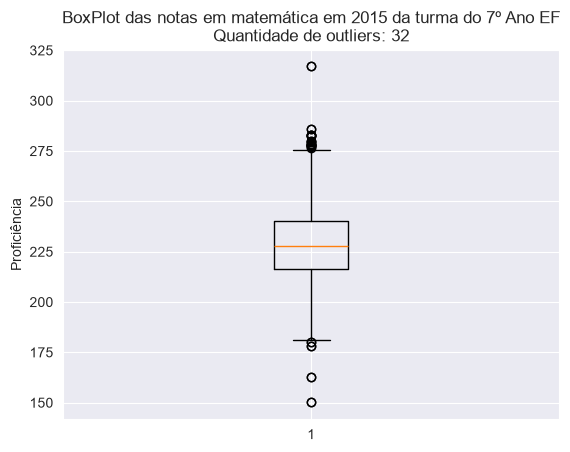

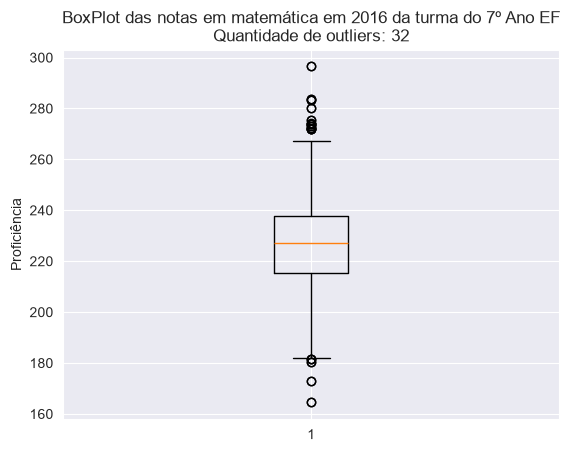

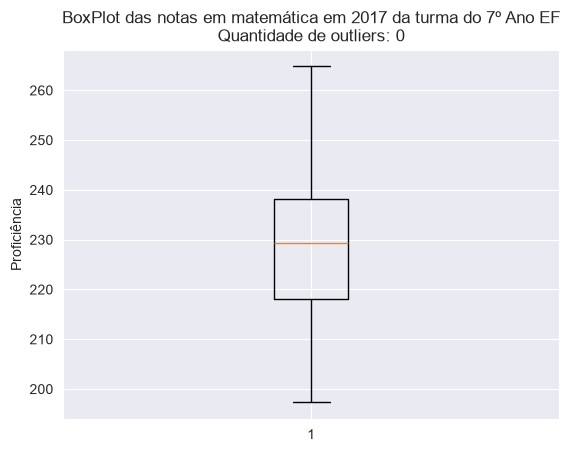

In [327]:
for dfi in lista_dataframes:
    x = dfi.loc[
        dfi['SERIE_ANO'].str.contains('7.*Ano EF', regex=True, na=False),
        'MEDPROF-N'
    ].dropna()

    if x.empty:
        continue

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = x[(x < limite_inferior) | (x > limite_superior)]

    plt.figure()
    plt.boxplot(x)
    plt.title(
        f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]} "
        f"da turma do 7º Ano EF\n"
        f"Quantidade de outliers: {len(outliers)}"
    )
    plt.ylabel('Proficiência')
    plt.show()
    #plt.savefig(f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]}.png", dpi=300, bbox_inches='tight')

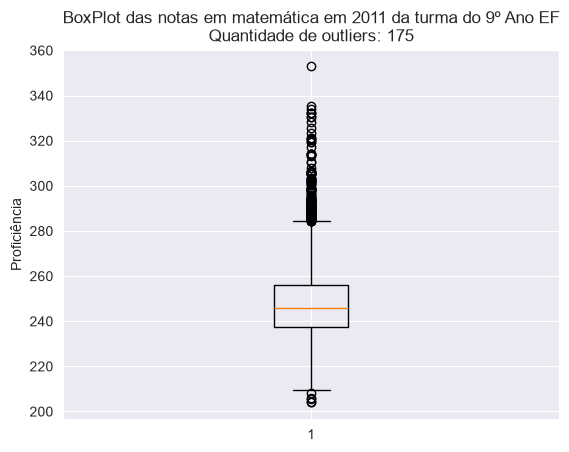

<Figure size 640x480 with 0 Axes>

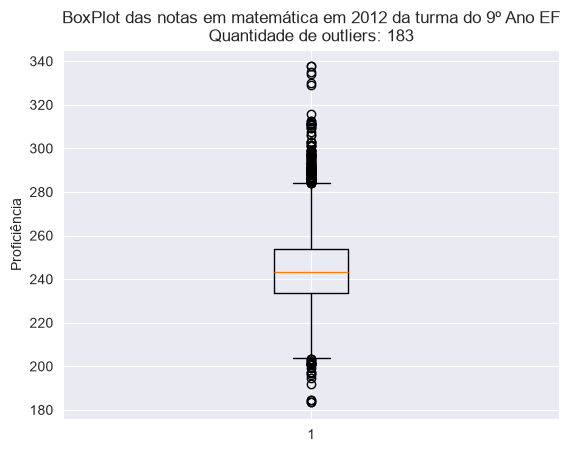

<Figure size 640x480 with 0 Axes>

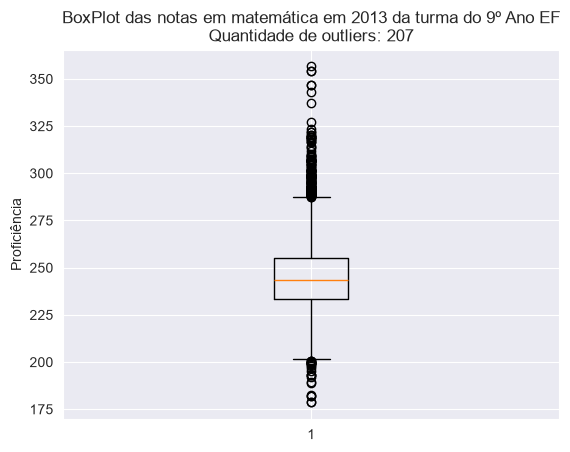

<Figure size 640x480 with 0 Axes>

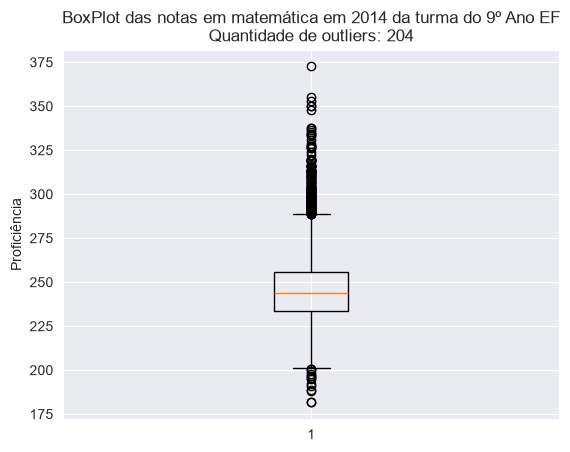

<Figure size 640x480 with 0 Axes>

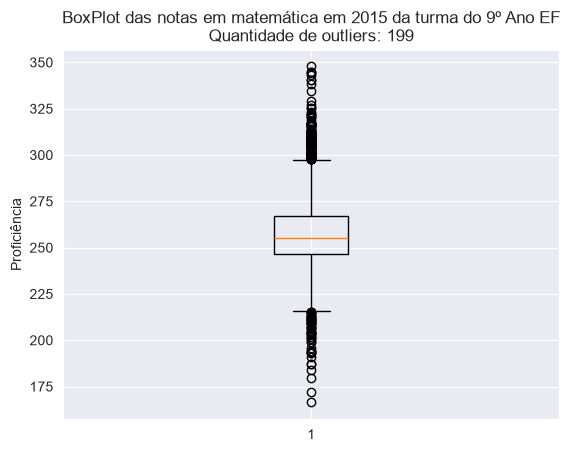

<Figure size 640x480 with 0 Axes>

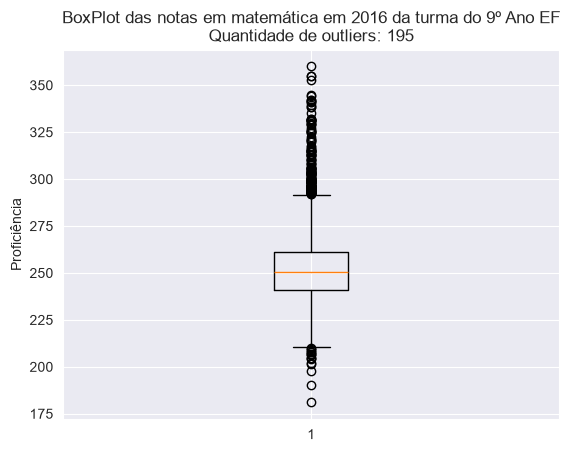

<Figure size 640x480 with 0 Axes>

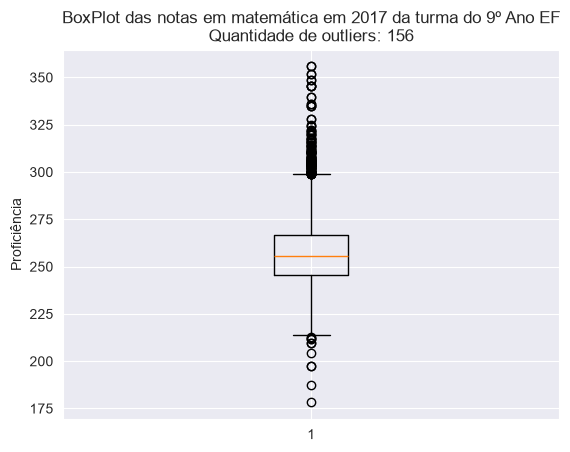

<Figure size 640x480 with 0 Axes>

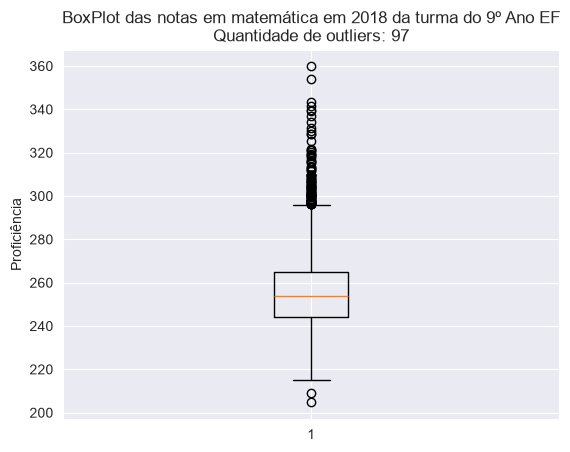

<Figure size 640x480 with 0 Axes>

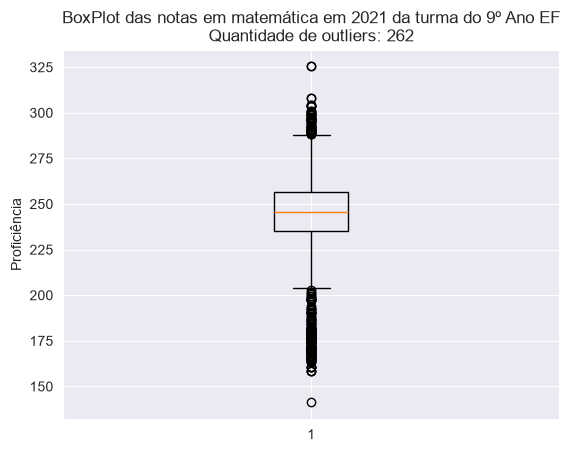

<Figure size 640x480 with 0 Axes>

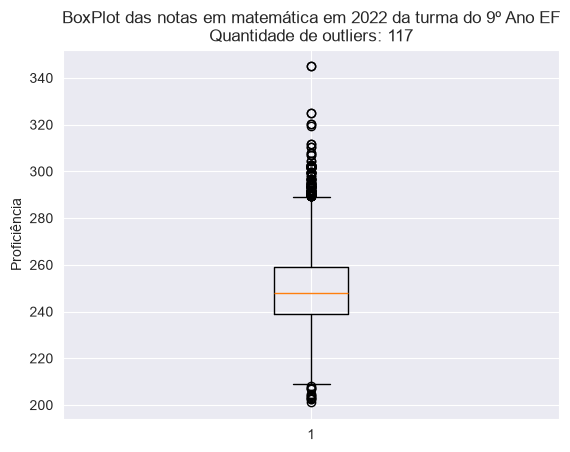

<Figure size 640x480 with 0 Axes>

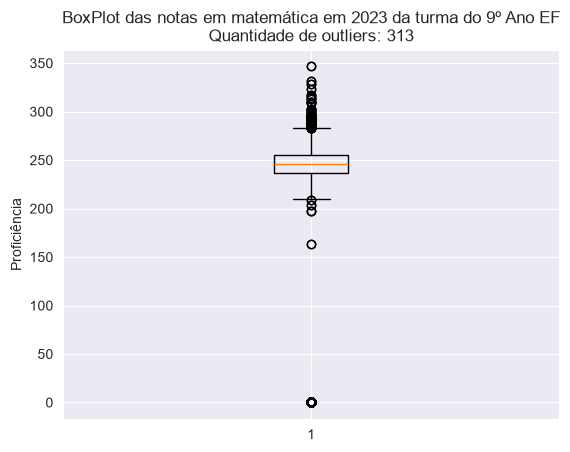

<Figure size 640x480 with 0 Axes>

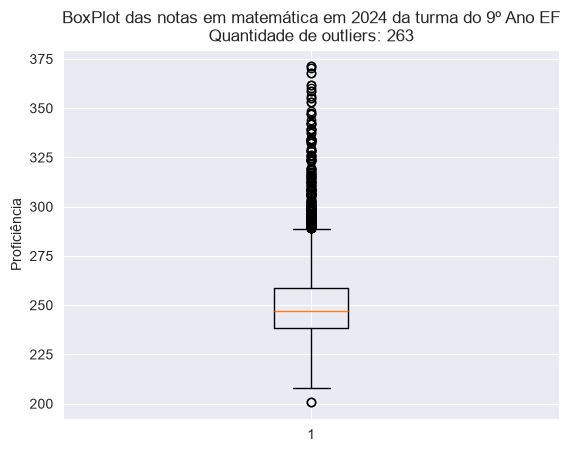

<Figure size 640x480 with 0 Axes>

In [324]:
for dfi in lista_dataframes:
    x = dfi.loc[
        dfi['SERIE_ANO'].str.contains('9.*Ano EF', regex=True, na=False),
        'MEDPROF-N'
    ].dropna()

    if x.empty:
        continue

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = x[(x < limite_inferior) | (x > limite_superior)]

    plt.figure()
    plt.boxplot(x)
    plt.title(
        f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]} "
        f"da turma do 9º Ano EF\n"
        f"Quantidade de outliers: {len(outliers)}"
    )
    plt.ylabel('Proficiência')
    plt.show()
    #plt.savefig(f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]}.png", dpi=300, bbox_inches='tight')

In [297]:
df_proficiencia_serasp_2021.loc[(df_proficiencia_serasp_2021['SERIE_ANO'] == '7º Ano EF')]

,DEPADM,DEPBOL,NOMEDEPBOL,CODESC,NOMESC,SERIE_ANO,COD_PER,PERIODO,CO_COMP,DS_COMP,MEDPROF,MEDPROF-N


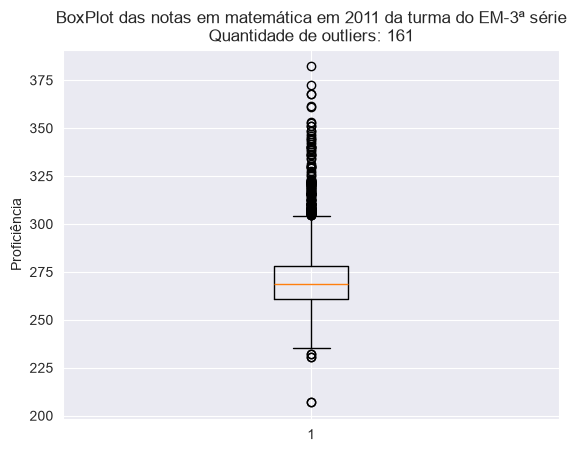

<Figure size 640x480 with 0 Axes>

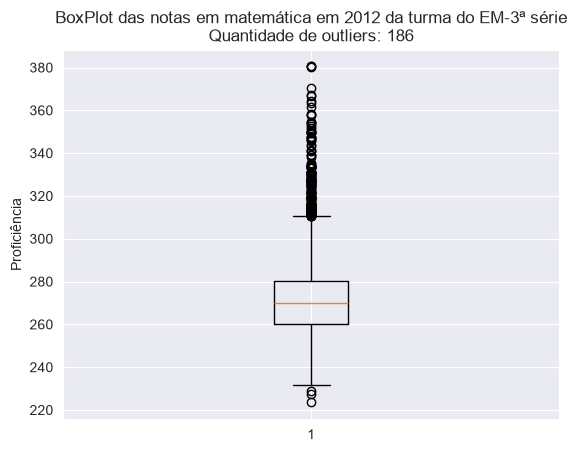

<Figure size 640x480 with 0 Axes>

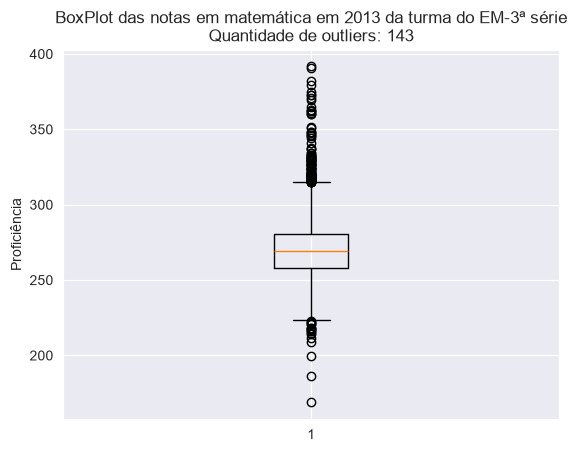

<Figure size 640x480 with 0 Axes>

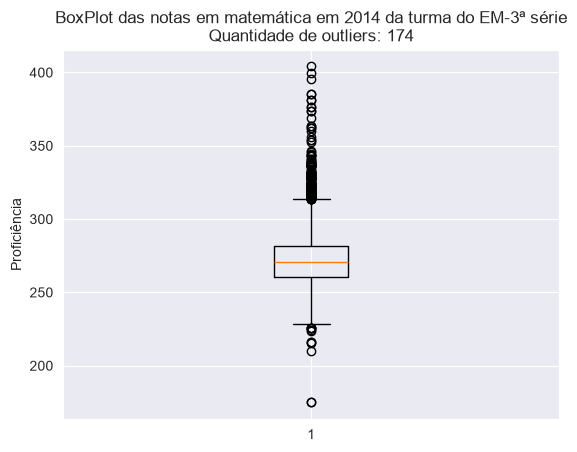

<Figure size 640x480 with 0 Axes>

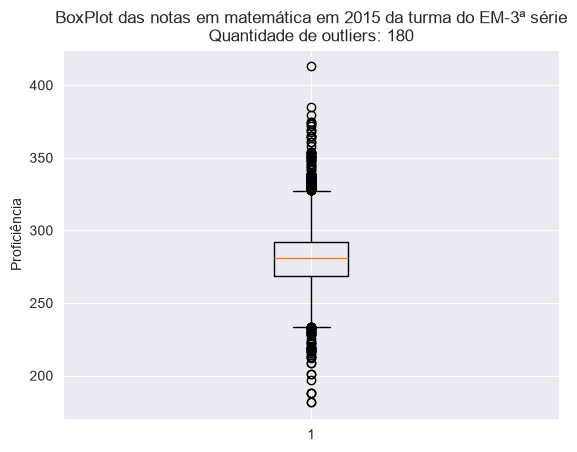

<Figure size 640x480 with 0 Axes>

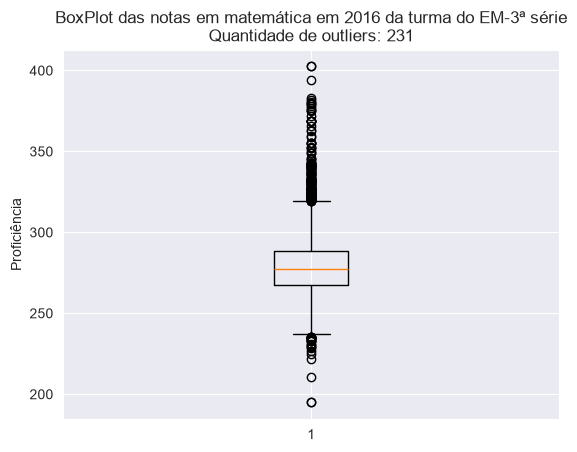

<Figure size 640x480 with 0 Axes>

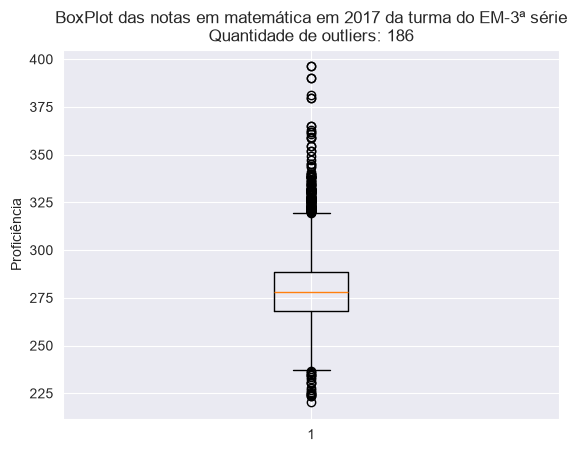

<Figure size 640x480 with 0 Axes>

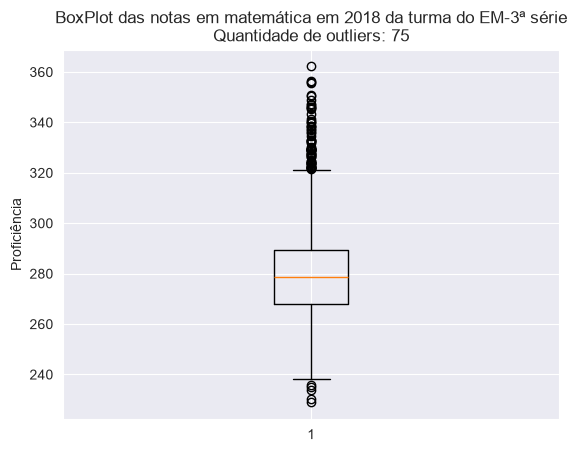

<Figure size 640x480 with 0 Axes>

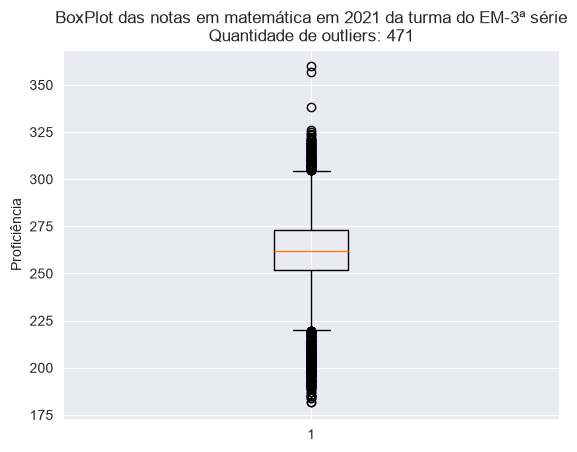

<Figure size 640x480 with 0 Axes>

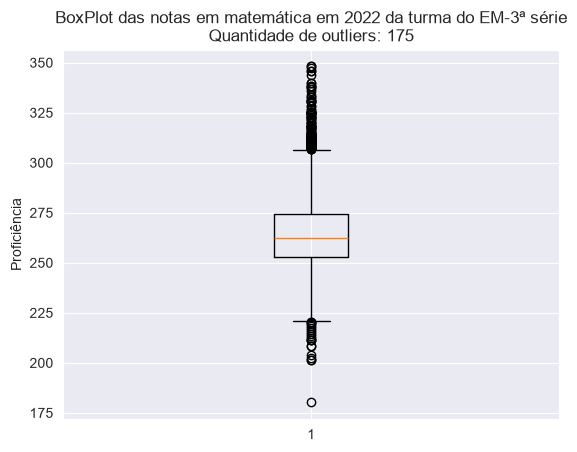

<Figure size 640x480 with 0 Axes>

In [325]:
for dfi in lista_dataframes:
    x = dfi.loc[
        dfi['SERIE_ANO'].str.contains('EM-3ª série', regex=True, na=False),
        'MEDPROF-N'
    ].dropna()

    if x.empty:
        continue

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = x[(x < limite_inferior) | (x > limite_superior)]

    plt.figure()
    plt.boxplot(x)
    plt.title(
        f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]} "
        f"da turma do EM-3ª série\n"
        f"Quantidade de outliers: {len(outliers)}"
    )
    plt.ylabel('Proficiência')
    plt.show()
    plt.savefig(f"BoxPlot das notas em matemática em {dfi['ANO'].iloc[0]}.png", dpi=300, bbox_inches='tight')

In [299]:
df_proficiencia_serasp_2025.loc[df_proficiencia_serasp_2025['SERIE_ANO']=='7° Ano EF']

,DEPADM,DepBol,NomeDepBol,codRMet,CODESC,NOMESC,SERIE_ANO,cod_per,periodo,co_comp,ds_comp,medprof,MEDPROF-N


In [302]:
df_proficiencia_serasp_2017

,DEPADM,DEPBOL,NOMEDEPBOL,CODESC,NOMESC,SERIE_ANO,COD_PER,PERIODO,CO_COMP,DS_COMP,MEDPROF,MEDPROF-N
0,1,1,Rede Estadual,12,AYRES DE MOURA PROFESSOR,9º Ano EF,1,MANHA,1,LÍNGUA PORTUGUESA,"261,3",261.3
1,1,1,Rede Estadual,12,AYRES DE MOURA PROFESSOR,9º Ano EF,1,MANHA,2,MATEMÁTICA,"270,9",270.9
2,1,1,Rede Estadual,12,AYRES DE MOURA PROFESSOR,9º Ano EF,9,GERAL,1,LÍNGUA PORTUGUESA,"261,3",261.3
3,1,1,Rede Estadual,12,AYRES DE MOURA PROFESSOR,9º Ano EF,9,GERAL,2,MATEMÁTICA,"270,9",270.9
4,1,1,Rede Estadual,24,GAVIAO PEIXOTO BRIGADEIRO,3º Ano EF,2,TARDE,1,LÍNGUA PORTUGUESA,157,157.0
...,...,...,...,...,...,...,...,...,...,...,...,...
56883,2,2,Rede Municipal,665186,JOANA MARIA DE GOES ESCOLA MUNICIPAL,5º Ano EF,9,GERAL,2,MATEMÁTICA,"234,9",234.9
56884,2,2,Rede Municipal,665344,MARIA TEREZA DE MELO EMEF,3º Ano EF,1,MANHA,1,LÍNGUA PORTUGUESA,166,166.0
56885,2,2,Rede Municipal,665344,MARIA TEREZA DE MELO EMEF,3º Ano EF,1,MANHA,2,MATEMÁTICA,"153,8",153.8
56886,2,2,Rede Municipal,665344,MARIA TEREZA DE MELO EMEF,3º Ano EF,9,GERAL,1,LÍNGUA PORTUGUESA,166,166.0
